# Radiomics from ovarian ultrasound: research demonstration

A presentation of the existing MMOTU OTU_2d experiment and its saved results. The cells read the dataset, saved feature configuration, aggregate comparison files, and existing figures; they do not fit models or rerun the experiment.

## 1. Research question

**Can quantitative radiomic features extracted from segmented ovarian ultrasound images help distinguish the eight official MMOTU diagnostic categories?**

This is a research demonstration and does not establish clinical validity or diagnostic utility.

## 2. Dataset

MMOTU OTU_2d contains **1,469 labeled images** in eight official categories. **1,269 images** have usable image and segmentation-mask files; **200 observations** were excluded because files or masks were missing or invalid. The label lists identify images by filename and do not provide reliable patient identifiers.

The table below shows the existing class distribution.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data import load_mmotu

DATA_ROOT = Path('data/raw/OTU_2d')
labels, data_audit = load_mmotu(DATA_ROOT)
class_distribution = pd.Series({
    'chocolate cyst': 336,
    'serous cystadenoma': 219,
    'teratoma': 336,
    'theca cell tumor': 88,
    'simple cyst': 66,
    'normal ovary': 267,
    'mucinous cystadenoma': 104,
    'high-grade serous carcinoma': 53,
}, name='labeled images').to_frame()
display(class_distribution)
display(pd.Series({
    'labeled images': 1469,
    'usable images with masks': 1269,
    'excluded observations': 200,
    'reliable patient identifiers available': False,
}, name='dataset summary').to_frame())

,labeled images
chocolate cyst,336
serous cystadenoma,219
teratoma,336
theca cell tumor,88
simple cyst,66
normal ovary,267
mucinous cystadenoma,104
high-grade serous carcinoma,53


,dataset summary
labeled images,1469
usable images with masks,1269
excluded observations,200
reliable patient identifiers available,False


## 3. Example image and segmentation mask

The mask defines the region of interest used for radiomic extraction. This example displays one existing image, its binary mask, and the mask overlay.

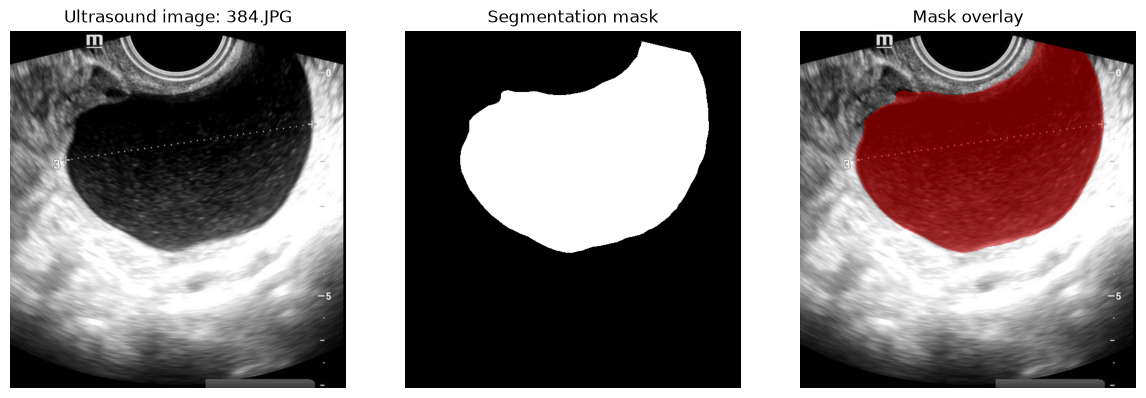

In [2]:
sample = labels.iloc[0]
with Image.open(sample.image_path) as image_file:
    image = np.asarray(image_file.convert('L'))
with Image.open(sample.mask_path) as mask_file:
    mask = np.asarray(mask_file.convert('L')) > 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image, cmap='gray')
axes[0].set_title(f"Ultrasound image: {sample.filename}")
axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Segmentation mask')
axes[2].imshow(image, cmap='gray')
axes[2].imshow(np.ma.masked_where(~mask, mask), cmap='autumn', alpha=0.45)
axes[2].set_title('Mask overlay')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

## 4. Radiomics extraction

PyRadiomics was applied to segmented ultrasound regions. The saved feature configuration contains **67 columns** across first-order, GLCM, GLRLM, and 2D shape families. Physical pixel spacing is unavailable; shape values are in pixel units and have no physical interpretation.

This summary reads the recorded extractor configuration; it does not rerun feature extraction.

In [3]:
feature_info = json.loads(Path('outputs/radiomics_config.json').read_text())
display(pd.Series({
    'engine': feature_info['engine'],
    'version': feature_info['pyradiomics_version'],
    'feature columns': len(feature_info['feature_names']),
    'feature families': ', '.join(feature_info['settings']['feature_classes']),
    'spacing': feature_info['settings']['spacing'],
}, name='saved radiomics configuration').to_frame())

,saved radiomics configuration
engine,PyRadiomics firstorder + GLCM + GLRLM + 2D shape
version,3.1.0a2.post8+g6a761c4
feature columns,67
feature families,"firstorder, glcm, glrlm, shape2D"
spacing,pixel units; physical spacing unavailable


## 5. Leakage-safe preprocessing

The model pipeline uses imputation, variance filtering, scaling, and mutual-information feature selection. These steps are fit **only on each training fold**, then applied to that fold's validation data. No feature selection or preprocessing is fit on the held-out official validation partition.

## 6. Validation design

Five-fold cross-validation was performed on the official training partition, with the official validation partition held out until final evaluation. The official validation partition was not used for tuning. The random seed was **42**. A duplicate-grouped cross-validation was also performed as a robustness analysis.

No patient-level independence can be claimed because reliable patient identifiers are unavailable.

## 7. Model results

The main CV table below reports the existing standard image-level CV results. The official validation metrics are shown separately. These are reported as model comparisons, not as clinical interpretations.

Logistic Regression has the smallest train–validation gap. Random Forest and XGBoost show larger gaps, consistent with greater overfitting; the more complex models achieve somewhat higher CV AUCs. Recall varies substantially across classes.

In [4]:
comparison = pd.read_csv('outputs/duplicate_safe_model_comparison.csv')
cv_results = comparison[[
    'model', 'original_cv_accuracy_mean', 'original_cv_accuracy_std',
    'original_cv_macro_f1_mean', 'original_cv_macro_f1_std',
    'original_cv_balanced_accuracy_mean', 'original_cv_balanced_accuracy_std',
    'original_cv_train_accuracy_mean', 'original_cv_train_validation_gap_mean',
]].rename(columns={
    'model': 'Model',
    'original_cv_accuracy_mean': 'Accuracy mean',
    'original_cv_accuracy_std': 'Accuracy SD',
    'original_cv_macro_f1_mean': 'Macro F1 mean',
    'original_cv_macro_f1_std': 'Macro F1 SD',
    'original_cv_balanced_accuracy_mean': 'Balanced accuracy mean',
    'original_cv_balanced_accuracy_std': 'Balanced accuracy SD',
    'original_cv_train_accuracy_mean': 'Train accuracy',
    'original_cv_train_validation_gap_mean': 'Train–validation gap',
})
display(cv_results.round(3))
validation_results = pd.DataFrame([
    ['Dummy', .269, .053, .125, .500, .808, 1.826],
    ['Logistic Regression', .480, .366, .395, .802, .686, 1.566],
    ['Random Forest', .540, .374, .376, .832, .584, 1.387],
    ['XGBoost', .560, .333, .339, .833, .582, 1.281],
], columns=['Model', 'Accuracy', 'Macro F1', 'Balanced accuracy', 'Macro OVR AUC', 'Brier score', 'Log loss'])
display(validation_results)
per_class_recall = pd.DataFrame({
    'Category': ['chocolate cyst', 'serous cystadenoma', 'teratoma', 'theca cell tumor', 'simple cyst', 'normal ovary', 'mucinous cystadenoma', 'high-grade serous carcinoma'],
    'Dummy': [0.00, 0.00, 1.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    'Logistic Regression': [0.54, 0.58, 0.61, 0.19, 0.32, 0.50, 0.09, 0.33],
    'Random Forest': [0.63, 0.67, 0.74, 0.35, 0.21, 0.15, 0.12, 0.13],
    'XGBoost': [0.76, 0.68, 0.80, 0.10, 0.16, 0.05, 0.03, 0.13],
})
display(per_class_recall)

,Model,Accuracy mean,Accuracy SD,Macro F1 mean,Macro F1 SD,Balanced accuracy mean,Balanced accuracy SD,Train accuracy,Train–validation gap
0,Dummy,0.263,0.003,0.052,0.000,0.125,0.000,0.263,0.000
1,Logistic Regression,0.478,0.047,0.367,0.050,0.396,0.050,0.504,0.027
2,Random Forest,0.549,0.053,0.394,0.078,0.388,0.067,0.976,0.427
3,XGBoost,0.535,0.033,0.314,0.044,0.322,0.033,0.787,0.252


,Model,Accuracy,Macro F1,Balanced accuracy,Macro OVR AUC,Brier score,Log loss
0,Dummy,0.269,0.053,0.125,0.500,0.808,1.826
1,Logistic Regression,0.480,0.366,0.395,0.802,0.686,1.566
2,Random Forest,0.540,0.374,0.376,0.832,0.584,1.387
3,XGBoost,0.560,0.333,0.339,0.833,0.582,1.281


,Category,Dummy,Logistic Regression,Random Forest,XGBoost
0,chocolate cyst,0.0,0.54,0.63,0.76
1,serous cystadenoma,0.0,0.58,0.67,0.68
2,teratoma,1.0,0.61,0.74,0.80
3,theca cell tumor,0.0,0.19,0.35,0.10
4,simple cyst,0.0,0.32,0.21,0.16
5,normal ovary,0.0,0.50,0.15,0.05
6,mucinous cystadenoma,0.0,0.09,0.12,0.03
7,high-grade serous carcinoma,0.0,0.33,0.13,0.13


## 8. Confusion matrices, ROC curves, and calibration

These are the existing figures for the official validation partition. Recall varies substantially across the eight categories; calibration and discrimination summaries are also reported in the tables above.

### Dummy baseline

<img src="outputs/figures/confusion_dummy.png" alt="Dummy confusion matrix" width="32%"> <img src="outputs/figures/roc_dummy.png" alt="Dummy ROC curves" width="32%"> <img src="outputs/figures/calibration_dummy.png" alt="Dummy calibration" width="32%">

### Logistic Regression

<img src="outputs/figures/confusion_logistic_regression.png" alt="Logistic Regression confusion matrix" width="32%"> <img src="outputs/figures/roc_logistic_regression.png" alt="Logistic Regression ROC curves" width="32%"> <img src="outputs/figures/calibration_logistic_regression.png" alt="Logistic Regression calibration" width="32%">

### Random Forest

<img src="outputs/figures/confusion_random_forest.png" alt="Random Forest confusion matrix" width="32%"> <img src="outputs/figures/roc_random_forest.png" alt="Random Forest ROC curves" width="32%"> <img src="outputs/figures/calibration_random_forest.png" alt="Random Forest calibration" width="32%">

### XGBoost

<img src="outputs/figures/confusion_xgboost.png" alt="XGBoost confusion matrix" width="32%"> <img src="outputs/figures/roc_xgboost.png" alt="XGBoost ROC curves" width="32%"> <img src="outputs/figures/calibration_xgboost.png" alt="XGBoost calibration" width="32%">

## 9. Robustness checks

The exact-duplicate audit found no duplicated modeling observations and no exact-duplicate groups crossing CV folds or the official train/validation boundary. Duplicate-grouped CV produced essentially unchanged results. The official validation set required no duplicate-based exclusions, and its metrics remained unchanged.

The existing macro-F1 chart summarizes duplicate-grouped CV by model. The table in the next section compares those values with standard image-level CV.

![Duplicate-grouped CV macro F1 by model](outputs/figures/cv_model_comparison.png)

## 10. Exact duplicate image audit

The audit inspected **1,886 physical source files** and identified **617 sets of duplicate physical source files**. Each labeled modeling observation was used only once. Zero duplicate groups crossed CV folds or the official train/validation boundary. The table compares existing original and duplicate-grouped CV values; no new model fitting is performed here.

In [5]:
duplicate_audit = json.loads(Path('outputs/duplicate_leakage_audit.json').read_text())
display(pd.Series({
    'physical source files inspected': duplicate_audit['n_source_image_files_audited'],
    'sets of duplicate physical source files': duplicate_audit['n_duplicate_groups'],
    'usable labeled modeling observations': duplicate_audit['n_model_observations'],
    'duplicate groups with multiple modeling observations': duplicate_audit['n_duplicate_groups_with_multiple_model_observations'],
    'duplicate groups crossing original CV folds': duplicate_audit['n_duplicate_groups_spanning_original_cv_folds'],
    'duplicate groups crossing official train/validation boundary': duplicate_audit['n_duplicate_groups_spanning_official_train_validation'],
    'validation images removed': duplicate_audit['contaminated_validation_images_removed'],
    'validation images before and after cleaning': f"{duplicate_audit['original_validation_image_count']} / {duplicate_audit['cleaned_validation_image_count']}",
}, name='exact duplicate audit').to_frame())
grouped_comparison = comparison[[
    'model', 'original_cv_accuracy_mean', 'duplicate_safe_cv_accuracy_mean',
    'original_cv_macro_f1_mean', 'duplicate_safe_cv_macro_f1_mean',
    'original_cv_balanced_accuracy_mean', 'duplicate_safe_cv_balanced_accuracy_mean',
    'original_cv_macro_ovr_auc_mean', 'duplicate_safe_cv_macro_ovr_auc_mean',
]].rename(columns={
    'model': 'Model',
    'original_cv_accuracy_mean': 'Original accuracy', 'duplicate_safe_cv_accuracy_mean': 'Grouped accuracy',
    'original_cv_macro_f1_mean': 'Original macro F1', 'duplicate_safe_cv_macro_f1_mean': 'Grouped macro F1',
    'original_cv_balanced_accuracy_mean': 'Original balanced accuracy', 'duplicate_safe_cv_balanced_accuracy_mean': 'Grouped balanced accuracy',
    'original_cv_macro_ovr_auc_mean': 'Original OVR AUC', 'duplicate_safe_cv_macro_ovr_auc_mean': 'Grouped OVR AUC',
})
display(grouped_comparison.round(3))
validation_comparison = comparison[[
    'model', 'original_official_validation_accuracy', 'duplicate_clean_official_validation_accuracy',
    'original_official_validation_macro_f1', 'duplicate_clean_official_validation_macro_f1',
    'original_official_validation_balanced_accuracy', 'duplicate_clean_official_validation_balanced_accuracy',
    'original_official_validation_macro_ovr_auc', 'duplicate_clean_official_validation_macro_ovr_auc',
]]
display(validation_comparison.round(3))

,exact duplicate audit
physical source files inspected,1886
sets of duplicate physical source files,617
usable labeled modeling observations,1269
duplicate groups with multiple modeling observations,0
duplicate groups crossing original CV folds,0
duplicate groups crossing official train/validation boundary,0
validation images removed,0
validation images before and after cleaning,402 / 402


,Model,Original accuracy,Grouped accuracy,Original macro F1,Grouped macro F1,Original balanced accuracy,Grouped balanced accuracy,Original OVR AUC,Grouped OVR AUC
0,Dummy,0.263,0.263,0.052,0.052,0.125,0.125,0.500,0.500
1,Logistic Regression,0.478,0.480,0.367,0.364,0.396,0.395,0.778,0.786
2,Random Forest,0.549,0.552,0.394,0.402,0.388,0.397,0.801,0.812
3,XGBoost,0.535,0.537,0.314,0.330,0.322,0.334,0.804,0.806


,model,original_official_validation_accuracy,duplicate_clean_official_validation_accuracy,original_official_validation_macro_f1,duplicate_clean_official_validation_macro_f1,original_official_validation_balanced_accuracy,duplicate_clean_official_validation_balanced_accuracy,original_official_validation_macro_ovr_auc,duplicate_clean_official_validation_macro_ovr_auc
0,Dummy,0.269,0.269,0.053,0.053,0.125,0.125,0.500,0.500
1,Logistic Regression,0.480,0.480,0.366,0.366,0.395,0.395,0.802,0.802
2,Random Forest,0.540,0.540,0.374,0.374,0.376,0.376,0.832,0.832
3,XGBoost,0.560,0.560,0.333,0.333,0.339,0.339,0.833,0.833


## 11. Methodological safeguards

- Imputation, variance filtering, scaling, and feature selection are fit within training folds.
- The held-out official validation partition is not used for tuning.
- Random seed = 42.
- No patient identifiers or clinical covariates are fabricated.
- No physical spacing is invented.
- The official eight-class labels are retained; no benign/malignant remapping is imposed.

## 12. Limitations

1. No reliable patient identifiers are available.
2. Patient-level independent validation cannot be claimed.
3. The evidence comes from one public dataset and acquisition context.
4. No external-center validation was performed.
5. Physical pixel spacing is unavailable.
6. Radiomic features may depend on annotation, display, and compression characteristics.
7. The results do not establish clinical validity or diagnostic utility.

## 13. Conclusion

This demonstration shows that a reproducible radiomics-to-ML workflow can be built on MMOTU ovarian ultrasound data, including leakage-aware preprocessing, model comparison, calibration, and robustness checks. More complex models achieved somewhat higher discrimination but also showed larger train–validation gaps. Exact duplicate leakage was investigated and did not materially affect performance. The experiment should be interpreted as a methodological demonstration rather than a clinically validated diagnostic model.